# 01dots: placing 3.2 million dots

PF7, "Kita: Malaysia in 3.2 million dots". One dot stands for 10 people counted in Census 2020.

How each dot gets its place and its attributes:

1. **How many dots, and which group**: from the 613 small areas of Census 2020 (600 state constituencies, DUN, plus the 13 parliamentary seats of the three Federal Territories, which have no DUN). Each area gives its population, its non-citizens, and the shares of Bumiputera, Chinese, Indian and other citizens.
2. **Where inside the area**: the Kontur population grid (400 m H3 hexagons) sets the weights, so dots crowd where people live. Areas where Kontur has far fewer people than the census (Putrajaya, Putatan) get the missing people spread evenly over the area.
3. **Malay or other Bumiputera, sex and five-year age band**: from OpenDOSM population by district 2020, using the district each dot falls in.
4. **Urban or rural**: from the district counts in the census, given to the dots in the densest hexagons first.

Inside each small area the groups are mixed at random among the dots: the data say how many, not which street. Dots are modelled positions, not addresses.

Output: `data/processed/dots.parquet` (one row per dot) plus a check table and two preview pictures.

## 0. Settings

In [1]:
from pathlib import Path
import json
import time
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import h3
from shapely.geometry import Polygon
import matplotlib.pyplot as plt

ROOT = Path.cwd()                                   # <- run from the PF7 folder
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

PEOPLE_PER_DOT = 10                                 # <- 1 dot per 10 people
SEED = 2020                                         # <- random seed: same seed, same dots
FALLBACK_RATIO = 0.5                                # <- if Kontur has less than this share of an area's census people, fill the gap evenly
FALLBACK_RES = 9                                    # <- H3 resolution of the even fill (9 is about 170 m)
NEAREST_MAX_M = 5000                                # <- Kontur hexagons outside every area join the nearest area within this distance (metres)
JITTER_M = 120                                      # <- VISUAL: random nudge of each dot (metres) so hexagon edges do not show; 0 = none

GITHUB = "https://raw.githubusercontent.com/dosm-malaysia/data-open/main/datasets"
SOURCES = {
    "census_dun.csv": f"{GITHUB}/census/census_dun.csv",
    "census_parlimen.csv": f"{GITHUB}/census/census_parlimen.csv",
    "electoral_1_dun.geojson": f"{GITHUB}/geodata/electoral_1_dun.geojson",
    "electoral_0_parlimen.geojson": f"{GITHUB}/geodata/electoral_0_parlimen.geojson",
}
GROUPS = ["Malay", "Other Bumiputera", "Chinese", "Indian", "Other citizens", "Non-citizens"]
GROUP_KEYS = ["bumi_malay", "bumi_other", "chinese", "indian", "other_citizen", "other_noncitizen"]
AGES = ["0-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59", "60-64", "65-69", "70-74", "75-79", "80-84", "85+"]
COLOURS = ["#1b9e77", "#66a61e", "#d95f02", "#7570b3", "#e6ab02", "#888888"]   # VISUAL: preview colours only; the web page has its own palette
rng = np.random.default_rng(SEED)
t0 = time.time()

## 1. Download the small-area files (once)

In [2]:
for name, url in SOURCES.items():
    path = RAW / name
    if path.exists() and path.stat().st_size > 0:
        print(f"{name:32s} cached")
        continue
    r = requests.get(url, headers={"User-Agent": "Kita portfolio project"}, timeout=120)
    r.raise_for_status()
    path.write_bytes(r.content)
    print(f"{name:32s} downloaded {len(r.content) / 1e6:.2f} MB")

census_dun.csv                   downloaded 0.15 MB
census_parlimen.csv              downloaded 0.06 MB
electoral_1_dun.geojson          downloaded 2.24 MB
electoral_0_parlimen.geojson     downloaded 1.37 MB


## 2. The 613 small areas

DUN for the 13 states, parliamentary seats for Kuala Lumpur, Putrajaya and Labuan. Each gets a code `sa` and the number of dots for each group. Rounding uses the largest remainder, so the national total is exact.

In [3]:
def largest_remainder(values, total):
    values = np.asarray(values, dtype=float)
    if total <= 0 or values.sum() <= 0:
        return np.zeros(len(values), dtype=np.int64)
    exact = values / values.sum() * total
    base = np.floor(exact).astype(np.int64)
    short = int(total - base.sum())
    order = np.argsort(-(exact - base), kind="stable")
    base[order[:short]] += 1
    return base

In [4]:
dun = pd.read_csv(RAW / "census_dun.csv")
par = pd.read_csv(RAW / "census_parlimen.csv")
ft = par[par["state"].str.startswith("W.P.")].copy()
dun["sa"] = dun["code_state_dun"]
dun["sa_name"] = dun["dun"]
ft["sa"] = ft["code_state"].astype(str) + "_" + ft["code_parlimen"]
ft["sa_name"] = ft["parlimen"]
cols = ["sa", "sa_name", "state", "population_total", "nationality_citizen", "nationality_non_citizen", "ethnicity_proportion_bumi", "ethnicity_proportion_chinese", "ethnicity_proportion_indian", "ethnicity_proportion_other", "household_total"]
sa = pd.concat([dun[cols], ft[cols]], ignore_index=True)
print(len(sa), "small areas,", f"{sa['population_total'].sum():,} people")

613 small areas, 32,447,385 people


In [5]:
total_people = int(sa["population_total"].sum())
n_total = int(round(total_people / PEOPLE_PER_DOT))
sa["n_dots"] = largest_remainder(sa["population_total"], n_total)
eth = sa[["ethnicity_proportion_bumi", "ethnicity_proportion_chinese", "ethnicity_proportion_indian", "ethnicity_proportion_other"]].to_numpy() / 100
eth = eth / eth.sum(axis=1, keepdims=True)
people = np.column_stack([eth * sa[["nationality_citizen"]].to_numpy(), sa["nationality_non_citizen"].to_numpy()])
counts = np.vstack([largest_remainder(row, n) for row, n in zip(people, sa["n_dots"])])
sa[["n_bumi", "n_chinese", "n_indian", "n_other", "n_noncit"]] = counts
print(f"{n_total:,} dots")
print(sa[["n_bumi", "n_chinese", "n_indian", "n_other", "n_noncit"]].sum().to_string())

3,244,738 dots
n_bumi       2064920
n_chinese     689215
n_indian      199881
n_other        21619
n_noncit      269103


## 3. Shapes and Kontur weights

Each Kontur hexagon joins the small area and the district that contain its centre. Hexagons just outside every area (coast, river mouths) join the nearest area within 5 km.

In [6]:
g_dun = gpd.read_file(RAW / "electoral_1_dun.geojson")
g_par = gpd.read_file(RAW / "electoral_0_parlimen.geojson")
g_dun["sa"] = g_dun["code_state_dun"]
g_ft = g_par[g_par["state"].str.startswith("W.P.")].copy()
g_ft["sa"] = g_ft["code_state"].astype(str) + "_" + g_ft["code_parlimen"]
shapes = pd.concat([g_dun[["sa", "geometry"]], g_ft[["sa", "geometry"]]], ignore_index=True)
shapes = gpd.GeoDataFrame(shapes, geometry="geometry", crs=g_dun.crs)
districts = gpd.read_file(RAW / "administrative_2_district.geojson")
districts["did"] = np.arange(len(districts))
print(len(shapes), "area shapes,", len(districts), "district shapes, all areas have a shape:", set(sa["sa"]) == set(shapes["sa"]))

613 area shapes, 160 district shapes, all areas have a shape: True


In [7]:
kontur = gpd.read_file(RAW / "kontur_population_MY_20231101.gpkg")
hexes = kontur[["h3", "population"]].copy()
hexes = gpd.GeoDataFrame(hexes, geometry=kontur.geometry.centroid, crs=kontur.crs).to_crs(4326)
j = gpd.sjoin(hexes, shapes, how="left", predicate="within")
j = j[~j.index.duplicated(keep="first")]
hexes["sa"] = j["sa"]
missing = hexes["sa"].isna()
near = gpd.sjoin_nearest(hexes[missing].to_crs(3857), shapes.to_crs(3857), how="left", max_distance=NEAREST_MAX_M)
near = near[~near.index.duplicated(keep="first")]
hexes.loc[missing, "sa"] = near["sa_right"] if "sa_right" in near.columns else near["sa"]
print(f"hexagons {len(hexes):,}; joined by nearest {missing.sum():,}; still outside {hexes['sa'].isna().sum():,} ({hexes.loc[hexes['sa'].isna(), 'population'].sum():,.0f} people, dropped)")
hexes = hexes[hexes["sa"].notna()].copy()

hexagons 147,936; joined by nearest 3,547; still outside 258 (794 people, dropped)


### Areas where Kontur falls short

If Kontur holds less than half of an area's census people, the gap is filled with an even layer of small H3 cells over the whole area.

In [8]:
k_sum = hexes.groupby("sa")["population"].sum()
sa["kontur"] = sa["sa"].map(k_sum).fillna(0)
sa["kratio"] = sa["kontur"] / sa["population_total"]
short = sa[sa["kratio"] < FALLBACK_RATIO]
print(len(short), "areas below the threshold:")
print(short[["sa", "sa_name", "state", "population_total", "kontur", "kratio"]].round(2).to_string(index=False))

3 areas below the threshold:
      sa              sa_name          state  population_total  kontur  kratio
 12_N.23         N.23 Petagas          Sabah             35844  3159.0    0.09
 12_N.24 N.24 Tanjung Keramat          Sabah             42126  8529.0    0.20
16_P.125      P.125 Putrajaya W.P. Putrajaya            109202  8451.0    0.08


In [9]:
def polygon_cells(geom, res):
    parts = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
    out = []
    for part in parts:
        shell = [(y, x) for x, y in part.exterior.coords]
        holes = [[(y, x) for x, y in ring.coords] for ring in part.interiors]
        out.extend(h3.polygon_to_cells(h3.LatLngPoly(shell, *holes), res))
    return out


fill_rows = []
shape_by_sa = shapes.set_index("sa")["geometry"]
for row in short.itertuples():
    cells = polygon_cells(shape_by_sa[row.sa], FALLBACK_RES)
    if len(cells) == 0:
        continue
    gap = row.population_total - row.kontur
    for c in cells:
        fill_rows.append((c, gap / len(cells), row.sa))
fill = pd.DataFrame(fill_rows, columns=["h3", "population", "sa"])
print(f"{len(fill):,} fill cells added")

676 fill cells added


## 4. Dots per hexagon

All weights (Kontur hexagons and fill cells) in one table. Each area's dots are shared among its cells by the largest remainder.

In [10]:
w = pd.concat([hexes[["h3", "population", "sa"]], fill], ignore_index=True)
w = w[w["population"] > 0].reset_index(drop=True)
n_by_sa = sa.set_index("sa")["n_dots"]
w["n"] = 0
for key, idx in w.groupby("sa").indices.items():
    w.loc[w.index[idx], "n"] = largest_remainder(w["population"].to_numpy()[idx], int(n_by_sa[key]))
print(f"cells with at least one dot {(w['n'] > 0).sum():,}; dots {w['n'].sum():,} (target {n_total:,})")
no_cells = set(sa["sa"]) - set(w["sa"])
print("areas with no cell at all:", no_cells)

cells with at least one dot 95,349; dots 3,244,738 (target 3,244,738)
areas with no cell at all: set()


## 5. Random points inside each cell

A point is drawn uniformly inside the hexagon: pick one of its six triangles, then a random point in that triangle. A small random nudge (JITTER_M) then softens the hexagon edges.

In [11]:
w = w[w["n"] > 0].reset_index(drop=True)
centres = np.array([h3.cell_to_latlng(c) for c in w["h3"]])
bounds = [h3.cell_to_boundary(c) for c in w["h3"]]
verts = np.array([b[:6] if len(b) >= 6 else (list(b) + [b[-1]] * (6 - len(b))) for b in bounds])
cell_idx = np.repeat(np.arange(len(w)), w["n"].to_numpy())
tri = rng.integers(0, 6, len(cell_idx))
a = centres[cell_idx]
b = verts[cell_idx, tri]
c = verts[cell_idx, (tri + 1) % 6]
r1 = np.sqrt(rng.random(len(cell_idx)))
r2 = rng.random(len(cell_idx))
pts = (1 - r1)[:, None] * a + (r1 * (1 - r2))[:, None] * b + (r1 * r2)[:, None] * c
pts = pts + rng.normal(0, JITTER_M / 111320, pts.shape)
dots = pd.DataFrame({"lat": pts[:, 0], "lon": pts[:, 1], "sa": w["sa"].to_numpy()[cell_idx], "weight": w["population"].to_numpy()[cell_idx], "res": np.array([h3.get_resolution(x) for x in w["h3"]])[cell_idx]})
print(f"{len(dots):,} dots placed, {time.time() - t0:.0f} s so far")

3,244,738 dots placed, 6 s so far


## 6. District of each dot

Found by point in polygon. Dots that land just outside every district (on the coast) take the district of the nearest dot that has one.

In [12]:
gd = gpd.GeoDataFrame(dots[["lon", "lat"]], geometry=gpd.points_from_xy(dots["lon"], dots["lat"]), crs=4326)
jd = gpd.sjoin(gd, districts[["did", "geometry"]], how="left", predicate="within")
jd = jd[~jd.index.duplicated(keep="first")]
dots["did"] = jd["did"].to_numpy()
lost = dots["did"].isna()
print(f"dots outside every district: {lost.sum():,}")
if lost.any():
    nd = gpd.sjoin_nearest(gd[lost.to_numpy()].to_crs(3857), districts[["did", "geometry"]].to_crs(3857), how="left")
    nd = nd[~nd.index.duplicated(keep="first")]
    dots.loc[lost, "did"] = nd["did"].to_numpy()
dots["did"] = dots["did"].astype(int)

dots outside every district: 45,893


## 7. Group of each dot

Within each small area the area's group counts are shuffled over its dots. Bumiputera dots are then split into Malay and other Bumiputera with the share of their district.

In [13]:
pop = pd.read_parquet(RAW / "population_district.parquet")
pop = pop[pd.to_datetime(pop["date"]).dt.year == 2020].copy()
dkey = districts[["state", "district", "did"]].copy()
dkey["k"] = dkey["state"].str.lower() + "|" + dkey["district"].str.lower()
pop["k"] = pop["state"].str.lower() + "|" + pop["district"].str.lower()
pop = pop.merge(dkey[["k", "did"]], on="k", how="left")
print("population rows without a district shape:", pop["did"].isna().sum())
eth_d = pop[(pop["sex"] == "both") & (pop["age"] == "overall")].pivot_table(index="did", columns="ethnicity", values="population", aggfunc="sum")
malay_share = (eth_d["bumi_malay"] / (eth_d["bumi_malay"] + eth_d["bumi_other"])).fillna(0.5)

population rows without a district shape: 0


In [14]:
dots = dots.sort_values("sa", kind="stable").reset_index(drop=True)
group = np.empty(len(dots), dtype=np.uint8)
start = 0
sa_counts = sa.set_index("sa")[["n_bumi", "n_chinese", "n_indian", "n_other", "n_noncit"]]
for key, n in dots.groupby("sa", sort=False).size().items():
    row = sa_counts.loc[key].to_numpy()
    labels = np.repeat(np.array([0, 2, 3, 4, 5], dtype=np.uint8), row)
    rng.shuffle(labels)
    group[start:start + n] = labels
    start += n
is_bumi = group == 0
p_malay = dots["did"].map(malay_share).to_numpy()
other_bumi = is_bumi & (rng.random(len(dots)) >= p_malay)
group[other_bumi] = 1
dots["group"] = group
print(pd.Series(group).map(dict(enumerate(GROUPS))).value_counts().reindex(GROUPS).to_string())

Malay               1692181
Other Bumiputera     372739
Chinese              689215
Indian               199881
Other citizens        21619
Non-citizens         269103


## 8. Sex and age of each dot

For each district and group, sex and five-year age band are drawn from that district's 2020 table for that group. Where a district has no one of a group in the table (rounded to zero), the state's mix for that group is used, and the national mix if the state has none either.

In [15]:
cells_ = pop[(pop["sex"] != "both") & (pop["age"] != "overall") & (pop["ethnicity"] != "overall")].copy()
cells_["g"] = cells_["ethnicity"].map({k: i for i, k in enumerate(GROUP_KEYS)})
cells_["s"] = cells_["sex"].map({"male": 0, "female": 1})
cells_["a"] = cells_["age"].map({k: i for i, k in enumerate(AGES)})
cells_["sa_cell"] = cells_["s"] * len(AGES) + cells_["a"]
n_cat = 2 * len(AGES)
table_d = cells_.pivot_table(index=["did", "g"], columns="sa_cell", values="population", aggfunc="sum").reindex(columns=range(n_cat)).fillna(0)
table_s = cells_.pivot_table(index=["state", "g"], columns="sa_cell", values="population", aggfunc="sum").reindex(columns=range(n_cat)).fillna(0)
did_state = districts.set_index("did")["state"]

In [16]:
sexage = np.empty(len(dots), dtype=np.int16)
fallbacks = 0
for (d, g), idx in dots.groupby(["did", "group"]).indices.items():
    p = table_d.loc[(d, g)].to_numpy() if (d, g) in table_d.index else np.zeros(n_cat)
    if p.sum() <= 0:
        st = did_state[d]
        p = table_s.loc[(st, g)].to_numpy() if (st, g) in table_s.index else np.zeros(n_cat)
        fallbacks += 1
    if p.sum() <= 0:
        p = table_s.xs(g, level="g").sum().to_numpy()
    sexage[idx] = rng.choice(n_cat, size=len(idx), p=p / p.sum())
dots["sex"] = (sexage // len(AGES)).astype(np.uint8)
dots["age"] = (sexage % len(AGES)).astype(np.uint8)
print("district and group pairs that used the state mix:", fallbacks)

district and group pairs that used the state mix: 204


## 9. Urban or rural

Each district has a census count of urban people. That many dots (divided by 10) are marked urban, taking the dots from the densest cells first. Density is people per cell, adjusted for cell size.

In [17]:
census = pd.read_csv(RAW / "census_district.csv")
census = census[census["year"] == 2020].copy()
census["k"] = census["state"].str.lower() + "|" + census["district"].str.lower()
census = census.merge(dkey[["k", "did"]], on="k", how="left")
census["urban"] = pd.to_numeric(census["density_urban"], errors="coerce").fillna(0)
urban_share_d = (census.set_index("did")["urban"] / census.set_index("did")["population_total"]).fillna(0)
cell_area = {8: 1.0, 9: 1 / 7}
dots["density"] = dots["weight"] / dots["res"].map(cell_area).fillna(1.0)
urban = np.zeros(len(dots), dtype=np.uint8)
for d, idx in dots.groupby("did").indices.items():
    k = int(round(len(idx) * urban_share_d.get(d, 0)))
    if k <= 0:
        continue
    order = idx[np.argsort(-(dots["density"].to_numpy()[idx] + rng.random(len(idx)) * 1e-6))]
    urban[order[:k]] = 1
dots["urban"] = urban
print(f"urban share of dots {urban.mean():.1%} (census 75.1%)")

urban share of dots 75.2% (census 75.1%)


## 10. Save

In [18]:
dots_out = pd.DataFrame()
dots_out["lon"] = dots["lon"].astype(np.float32)
dots_out["lat"] = dots["lat"].astype(np.float32)
dots_out["group"] = dots["group"].astype(np.uint8)
dots_out["sex"] = dots["sex"].astype(np.uint8)
dots_out["age"] = dots["age"].astype(np.uint8)
dots_out["urban"] = dots["urban"].astype(np.uint8)
dots_out["did"] = dots["did"].astype(np.int16)
dots_out["sa"] = dots["sa"].astype("category")
dots_out = dots_out.sample(frac=1, random_state=SEED).reset_index(drop=True)
dots_out.to_parquet(OUT / "dots.parquet", index=False)
sa.to_csv(OUT / "small_areas.csv", index=False)
meta = {"people_per_dot": PEOPLE_PER_DOT, "seed": SEED, "n_dots": int(len(dots_out)), "groups": GROUPS, "ages": AGES, "sex": ["Male", "Female"], "urban": ["Rural", "Urban"], "census_year": 2020, "small_areas": int(len(sa)), "fallback_areas": short["sa_name"].tolist()}
(OUT / "dots_meta.json").write_text(json.dumps(meta, indent=2))
print(f"saved {len(dots_out):,} dots, {(OUT / 'dots.parquet').stat().st_size / 1e6:.1f} MB, {time.time() - t0:.0f} s in all")

saved 3,244,738 dots, 40.6 MB, 17 s in all


## 11. Checks against the census

Dots times 10 against the census, nationally and by district. District totals are not exact by design, because the small areas do not nest inside districts.

In [19]:
chk = pd.DataFrame({"dots x 10": dots_out["group"].value_counts().sort_index().to_numpy() * PEOPLE_PER_DOT}, index=GROUPS)
chk["population_district 2020"] = [eth_d[k].sum() * 1000 for k in GROUP_KEYS]
chk["difference"] = (chk["dots x 10"] / chk["population_district 2020"] - 1).map("{:+.1%}".format)
print(chk.round(0).to_string())

                  dots x 10  population_district 2020 difference
Malay              16921810                16912600.0      +0.1%
Other Bumiputera    3727390                 3736300.0      -0.2%
Chinese             6892150                 6891900.0      +0.0%
Indian              1998810                 1997900.0      +0.0%
Other citizens       216190                  215900.0      +0.1%
Non-citizens        2691030                 2690600.0      +0.0%


In [20]:
by_d = dots_out.groupby("did").size() * PEOPLE_PER_DOT
cmp = census.set_index("did")[["state", "district", "population_total"]].join(by_d.rename("dots x 10"))
cmp["error"] = cmp["dots x 10"] / cmp["population_total"] - 1
print(cmp["error"].abs().describe().round(3).to_string())
print("largest district differences:")
print(cmp.reindex(cmp["error"].abs().sort_values(ascending=False).index).head(8).round(3).to_string())

count    160.000
mean       0.040
std        0.098
min        0.000
25%        0.004
50%        0.009
75%        0.028
max        0.745
largest district differences:
        state       district  population_total  dots x 10  error
did                                                             
147   Sarawak       Selangau           19844.0       5060 -0.745
151   Sarawak  Tanjung Manis            7946.0      13450  0.693
32   Kelantan   Kecil Lojing           10609.0      16010  0.509
121   Sarawak         Serian           85345.0      61050 -0.285
155   Sarawak         Beluru           28695.0      22560 -0.214
156   Sarawak    Telang Usan           17406.0      13790 -0.208
128   Sarawak       Maradong           20299.0      16490 -0.188
144   Sarawak           Matu           16316.0      19330  0.185


In [21]:
pyr = dots_out.groupby(["age", "sex"]).size().unstack() * PEOPLE_PER_DOT
pyr.index = AGES
pyr.columns = ["Male", "Female"]
print(pyr.to_string())

          Male   Female
0-4    1287400  1231420
5-9    1368320  1273470
10-14  1352230  1260620
15-19  1497910  1346930
20-24  1549260  1324770
25-29  1595070  1309900
30-34  1569410  1339030
35-39  1474050  1280060
40-44  1170670  1026420
45-49   956790   882770
50-54   800680   776280
55-59   739370   712510
60-64   576610   576090
65-69   454790   458020
70-74   294080   313030
75-79   154110   168900
80-84    88980   104610
85+      64520    68300


## 12. Preview pictures

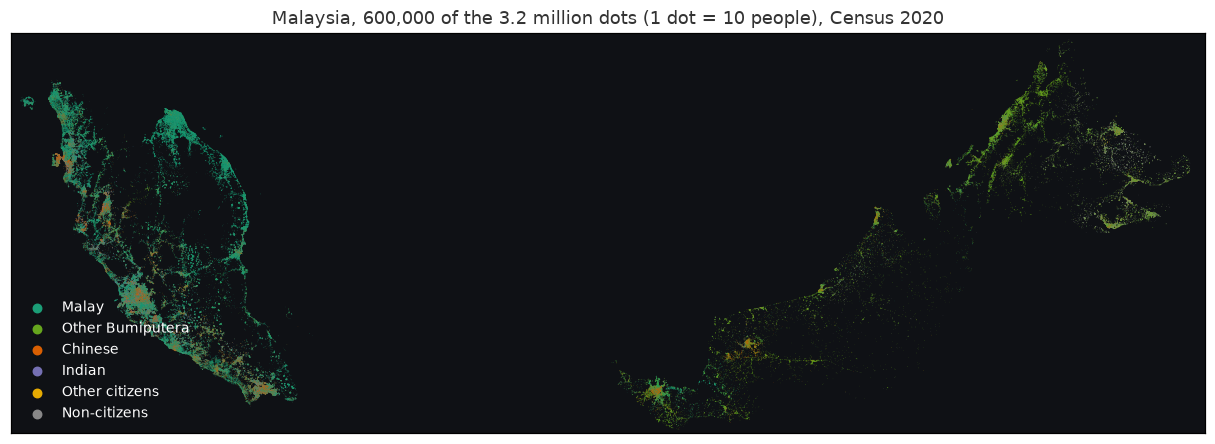

In [22]:
show = dots_out.sample(600_000, random_state=1)
fig, ax = plt.subplots(figsize=(14, 6.5), dpi=110)
ax.set_facecolor("#0f1115")
ax.scatter(show["lon"], show["lat"], s=0.05, c=np.array(COLOURS)[show["group"]], linewidths=0)
ax.set_xlim(99.5, 119.5)
ax.set_ylim(0.8, 7.5)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
for i, name in enumerate(GROUPS):
    ax.scatter([], [], s=30, c=COLOURS[i], label=name)
ax.legend(loc="lower left", frameon=False, labelcolor="white", fontsize=9)
ax.set_title("Malaysia, 600,000 of the 3.2 million dots (1 dot = 10 people), Census 2020", color="#333")
fig.savefig(OUT / "preview_malaysia.png", bbox_inches="tight")
plt.show()

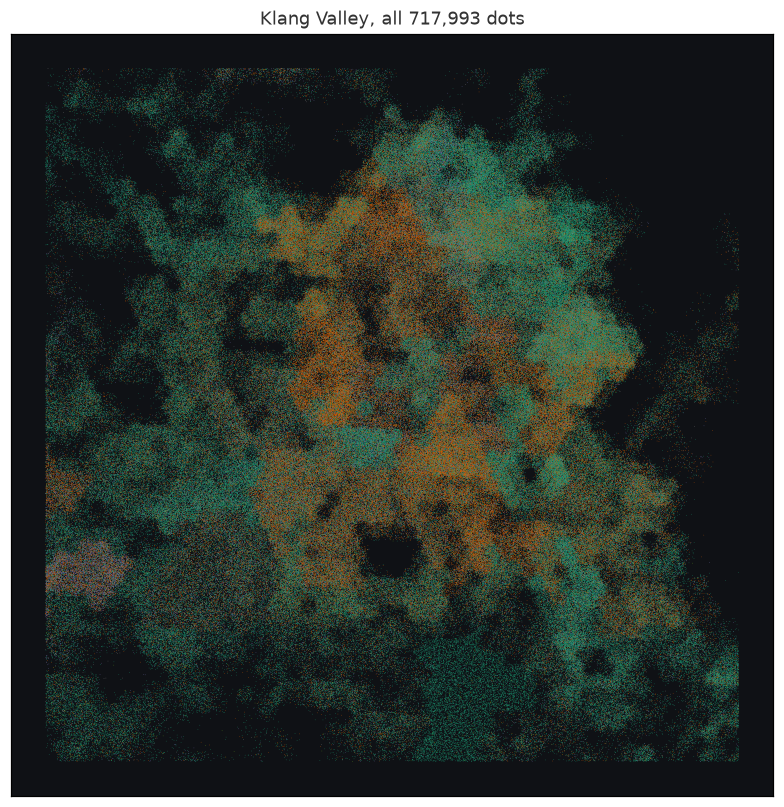

In [23]:
kl = dots_out[(dots_out["lon"].between(101.45, 101.85)) & (dots_out["lat"].between(2.9, 3.3))]
fig, ax = plt.subplots(figsize=(9, 9), dpi=110)
ax.set_facecolor("#0f1115")
ax.scatter(kl["lon"], kl["lat"], s=0.15, c=np.array(COLOURS)[kl["group"]], linewidths=0)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f"Klang Valley, all {len(kl):,} dots", color="#333")
fig.savefig(OUT / "preview_klangvalley.png", bbox_inches="tight")
plt.show()

___

**END**